# Customer Churn Prediction — Supervised Machine Learning

**Inovegen AI/ML Internship Program 2026 — Task 3: Customer Churn Prediction**

This project builds a supervised machine-learning **classification model** that predicts whether a telecom customer will churn (cancel their service), using the IBM Telco Customer Churn dataset. It applies the same data cleaning, preprocessing, and evaluation workflow practiced in Tasks 1 and 2 to a new, independent real-world dataset.

## 2. Project Objective

**Customer churn** refers to a customer ending their relationship with a company — in this case, cancelling their telecom service.

This is a **binary classification problem** because the target variable, `Churn`, has exactly two possible values: the customer either churned (`Yes`) or did not churn (`No`).

The objective of this notebook is to build a model that predicts, from a customer's account and service details (such as contract type, tenure, and monthly charges), whether that customer is likely to churn.

**Why this is useful:** if a business can identify customers who are statistically likely to churn, it can proactively reach out to them (e.g., with retention offers) before they leave.

**Important caveat:** the model identifies statistical patterns and associations in this historical dataset. It does **not** determine, with certainty, *why* any individual customer churns — many real-world factors are not captured in this dataset.

## 3. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (7, 5)
pd.set_option("display.max_columns", None)

## 4. Load Dataset

**Dataset/source reference:** IBM Telco Customer Churn dataset, loaded directly from the uploaded file `WA_Fn-UseC_-Telco-Customer-Churn.csv` (commonly available via Kaggle: https://www.kaggle.com/datasets/blastchar/telco-customer-churn). The uploaded CSV is used as the sole data source for this analysis.

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())

Shape: (7043, 21)

Columns: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Structure of the dataset:** each row represents one customer, with 21 columns covering a unique customer identifier (`customerID`), demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account details (`tenure`, `Contract`, `PaymentMethod`, `PaperlessBilling`, `MonthlyCharges`, `TotalCharges`), the services subscribed to (`PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`), and the target (`Churn`).

## 5. Initial Data Inspection

In [5]:
df.shape

(7043, 21)

In [6]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
df.describe(include="all")

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [9]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

**Findings:**
- The dataset has **7,043 rows and 21 columns**.
- `pandas.isnull()` reports **0 missing values** across all columns at first glance — but `TotalCharges` is stored as an **object (text) column** rather than numeric, which is suspicious for a column that should represent a dollar amount. This is investigated in the next section.
- There are **no duplicate rows**.
- `SeniorCitizen` is stored as an integer (0/1) while similar columns like `Partner`/`Dependents` use `"Yes"/"No"` text — a minor inconsistency, but not an error, so it is left as-is since 0/1 is already numeric and usable.
- Most other columns are categorical text fields describing customer demographics and subscribed services.

## 6. Data Cleaning

Each cleaning decision below follows: **what was found → why it matters → what was done → why that approach fits this data.**

## 7. Handle `TotalCharges`

**Problem:** `TotalCharges` is stored as an object (text) column, not a number, even though it represents a dollar amount. This suggests it contains non-numeric values such as blank strings.

**Why it matters:** a numeric column stored as text can't be used directly in calculations, statistics, or the model, and hidden blank strings won't show up in a standard `isnull()` check.

In [11]:
# Attempt to convert TotalCharges to numeric; invalid/blank entries become NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Missing values in TotalCharges after conversion:", df["TotalCharges"].isnull().sum())

Missing values in TotalCharges after conversion: 11


In [12]:
# Inspect the rows that became missing
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


**Finding:** converting `TotalCharges` to numeric reveals **11 blank values**, and every one of them belongs to a customer with **`tenure` = 0** — i.e., brand-new customers who haven't been billed yet. This isn't random missingness; it has a clear, logical explanation.

**Method chosen:** fill these 11 values with **0** (not the median), since a customer with zero tenure logically has zero total charges so far — using the dataset median here would invent a charge history that doesn't exist for these new customers.
**Why this is appropriate:** this is a targeted, logic-based fix rather than a generic imputation, and it affects only 11 of 7,043 rows (~0.16%), so it carries negligible risk of distorting the analysis.

In [13]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Remaining missing values in TotalCharges:", df["TotalCharges"].isnull().sum())

Remaining missing values in TotalCharges: 0


## 8. Remove Unsuitable Columns

**`customerID`** is a unique identifier string (e.g., `"7590-VHVEG"`) assigned to each customer. It does not describe any real customer characteristic or behavior, so it carries no predictive information — including it as a feature would not help the model learn genuine patterns, and a model could even overfit by "memorizing" IDs. It is excluded from the predictive features below (though it is kept in `df` for now, in case it's useful for reference).

No other columns show signs of being pure identifiers or otherwise unsuitable, so no further columns are removed at this stage.

In [14]:
print("Unique customerID values:", df["customerID"].nunique(), "out of", len(df), "rows")

Unique customerID values: 7043 out of 7043 rows


## 9. Exploratory Data Analysis

Before modeling, we explore the data visually to understand churn patterns.

### 9.1 Visualization 1 — Churn Distribution

How many customers churned vs. did not churn.

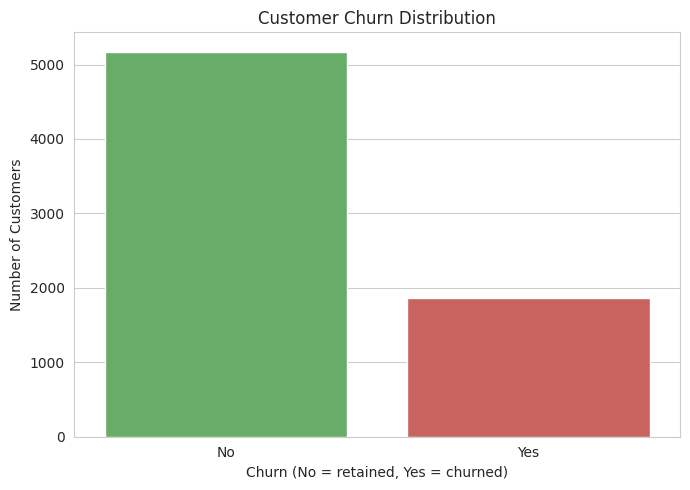

In [15]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="Churn", hue="Churn", palette=["#5cb85c", "#d9534f"], legend=False, ax=ax)
ax.set_title("Customer Churn Distribution")
ax.set_xlabel("Churn (No = retained, Yes = churned)")
ax.set_ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [16]:
print(df["Churn"].value_counts())
print()
print((df["Churn"].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


**Finding:** the dataset is **imbalanced** — about **73.5%** of customers did not churn (`No`) while about **26.5%** churned (`Yes`). This matters because a model could achieve ~73% accuracy just by always predicting "No churn," so accuracy alone would be a misleading measure of model quality here; precision, recall, and F1-score (calculated later) give a fuller picture.

### 9.2 Visualization 2 — Churn by Contract Type

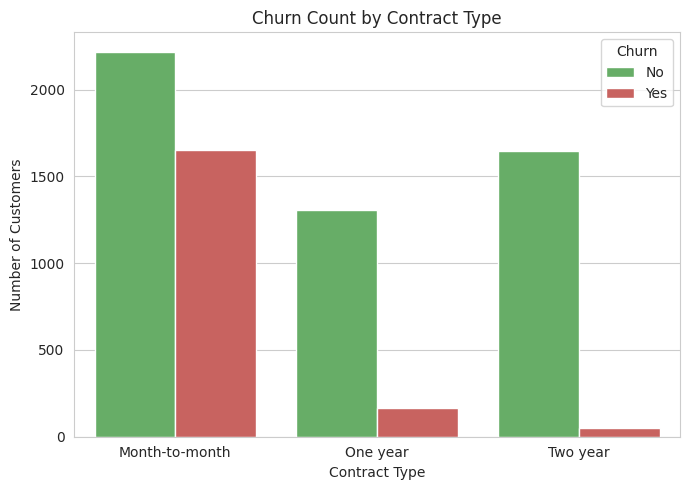

In [17]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="Contract", hue="Churn", palette=["#5cb85c", "#d9534f"], ax=ax)
ax.set_title("Churn Count by Contract Type")
ax.set_xlabel("Contract Type")
ax.set_ylabel("Number of Customers")
ax.legend(title="Churn")
plt.tight_layout()
plt.show()

In [18]:
contract_churn_rate = df.groupby("Contract")["Churn"].apply(lambda x: (x == "Yes").mean())
contract_churn_rate

Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319
Name: Churn, dtype: float64

**Finding:** churn rate was associated with contract type — **Month-to-month** customers showed a much higher churn rate than **One year** or **Two year** customers (see the calculated rates above). This suggests customers on longer, more committed contracts were less likely to leave, though this is an association observed in this dataset, not proof that contract length alone causes retention.

### 9.3 Visualization 3 — Tenure by Churn

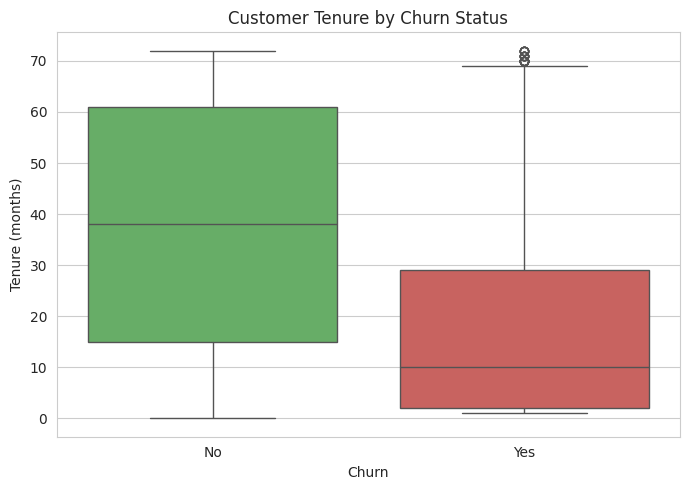

In [19]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Churn", y="tenure", hue="Churn", palette=["#5cb85c", "#d9534f"], legend=False, ax=ax)
ax.set_title("Customer Tenure by Churn Status")
ax.set_xlabel("Churn")
ax.set_ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

In [20]:
df.groupby("Churn")["tenure"].median()

Churn
No     38.0
Yes    10.0
Name: tenure, dtype: float64

**Finding:** customers who churned tended to have **much shorter tenure** (lower median months with the company) than customers who stayed, suggesting churn was associated with newer customers rather than long-standing ones.

### 9.4 Visualization 4 — Monthly Charges by Churn (Optional additional EDA)

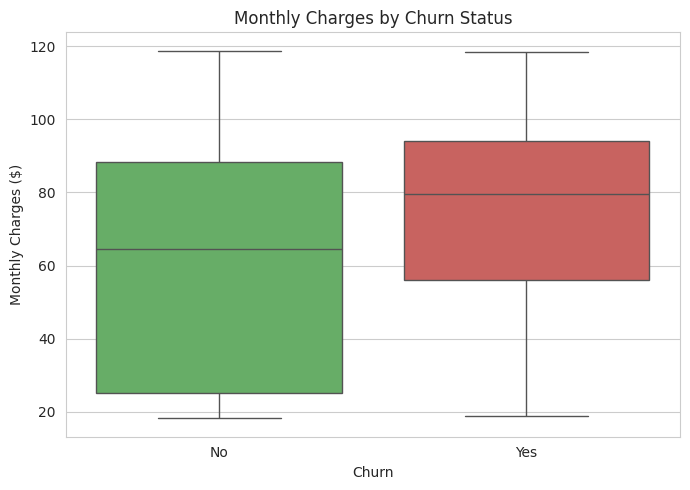

In [21]:
fig, ax = plt.subplots()
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", hue="Churn", palette=["#5cb85c", "#d9534f"], legend=False, ax=ax)
ax.set_title("Monthly Charges by Churn Status")
ax.set_xlabel("Churn")
ax.set_ylabel("Monthly Charges ($)")
plt.tight_layout()
plt.show()

In [22]:
df.groupby("Churn")["MonthlyCharges"].median()

Churn
No     64.425
Yes    79.650
Name: MonthlyCharges, dtype: float64

**Finding:** customers who churned tended to have **higher median monthly charges** than those who stayed, suggesting cost may be associated with the decision to leave.

### 9.5 Visualization 5 — Internet Service Type vs. Churn (Optional additional EDA)

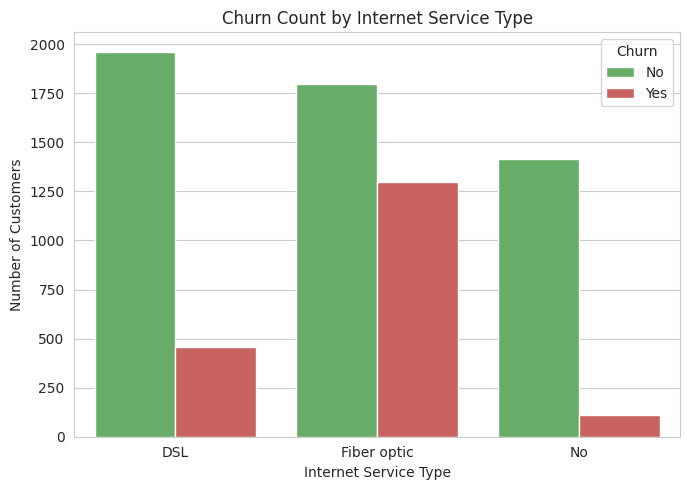

In [23]:
fig, ax = plt.subplots()
sns.countplot(data=df, x="InternetService", hue="Churn", palette=["#5cb85c", "#d9534f"], ax=ax)
ax.set_title("Churn Count by Internet Service Type")
ax.set_xlabel("Internet Service Type")
ax.set_ylabel("Number of Customers")
ax.legend(title="Churn")
plt.tight_layout()
plt.show()

In [24]:
internet_churn_rate = df.groupby("InternetService")["Churn"].apply(lambda x: (x == "Yes").mean())
internet_churn_rate

InternetService
DSL            0.189591
Fiber optic    0.418928
No             0.074050
Name: Churn, dtype: float64

**Finding:** churn rate differed by internet service type, with **Fiber optic** customers showing a notably higher churn rate than **DSL** customers or customers with **No** internet service (see calculated rates above).

## 10. Define Features and Target

`X` holds the **input features** the model will learn from; `y` holds the **target** we want to predict. The target `Churn` is text (`"Yes"`/`"No"`), so we map it to numeric 0/1 for use with Scikit-learn's classification metrics and models.

In [25]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(y.head())

Features shape: (7043, 19)
Target shape: (7043,)
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64


## 11. Check Target Distribution

In [26]:
print(y.value_counts())
print()
print(y.value_counts(normalize=True))

Churn
0    5174
1    1869
Name: count, dtype: int64

Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64


**Class imbalance:** as seen in Section 9.1, roughly **73.5%** of customers are class 0 (no churn) and **26.5%** are class 1 (churned). This confirms the dataset is imbalanced, which is why we use `stratify=y` in the train/test split below (to preserve this ratio in both sets) and why we look beyond accuracy alone when evaluating the model.

## 12. Identify Numerical and Categorical Features

Based on the actual columns in this dataset:

- **Numerical features:** `tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen` (already 0/1, treated as numeric).
- **Categorical features:** `gender`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `Contract`, `PaperlessBilling`, `PaymentMethod`.

In [27]:
numerical_features = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]
categorical_features = [col for col in X.columns if col not in numerical_features]

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 13. Train/Test Split

- **Training set:** the data the model learns patterns from.
- **Testing set:** data the model never sees during training, used only afterward to check how well it generalizes to new customers.
- `test_size=0.2` — 20% of customers are held out for testing.
- `random_state=42` — makes the split reproducible across runs.
- `stratify=y` — keeps the same ~73.5%/26.5% churn ratio in both the training and testing sets, which matters given the class imbalance confirmed above.

Keeping the test set unseen during training is essential — if information from it leaked into training (e.g., via preprocessing statistics computed on the full dataset), the evaluation results would look better than the model's real ability to generalize. This is called **data leakage**.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 5634
Testing samples: 1409


## 14. Preprocessing Pipeline

We build a `ColumnTransformer` inside a `Pipeline`:

1. Numerical columns: median imputation (as a safety net, though none are missing after Section 7) + `StandardScaler`.
2. Categorical columns: most-frequent imputation (safety net) + `OneHotEncoder(handle_unknown="ignore")`.

Because this preprocessing lives inside a `Pipeline`, it is **fit only on the training data** when we later call `.fit(X_train, y_train)`, and only *applied* (not re-fit) to the test data — this is what prevents data leakage.

In [29]:
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

## 15. Classification Model — Logistic Regression

**Logistic Regression** estimates the probability that a customer churns (a value between 0 and 1) and classifies them as "will churn" if that probability exceeds 0.5. It is a strong, simple, interpretable baseline for binary classification problems like this one.

- `model.fit(X_train, y_train)` — learns both the preprocessing statistics and the model's internal parameters from the training data only.
- `model.predict(X_test)` — uses what was learned during `fit()` to predict churn for the unseen test customers.

In [30]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=42))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("First 10 predictions:", y_pred[:10])
print("First 10 actual values:", y_test.values[:10])

First 10 predictions: [0 1 0 0 0 1 0 0 0 0]
First 10 actual values: [0 0 0 0 0 0 0 0 0 1]


## 16. Model Evaluation

- **Accuracy** — proportion of all predictions that were correct. Can be misleading here given the ~73.5%/26.5% class imbalance.
- **Precision** — of customers predicted to churn, what fraction actually churned? High precision means few false alarms (wasted retention offers).
- **Recall** — of customers who actually churned, what fraction did the model correctly catch? High recall means few missed churners.
- **F1-score** — the balance between precision and recall.

In [31]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

Accuracy:  0.806
Precision: 0.657
Recall:    0.559
F1-score:  0.604


## 17. Classification Report

In [32]:
print(classification_report(y_test, y_pred, target_names=["No churn", "Churn"]))

              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



**In beginner-friendly terms:** the report above shows precision, recall, and F1-score calculated separately for each class. Comparing the "No churn" row to the "Churn" row (using the actual values above) shows whether the model is better at correctly identifying customers who stay versus customers who leave — which, given the class imbalance, is often not the same.

## 18. Confusion Matrix

- **True Negative (TN):** predicted "No churn", actually did not churn.
- **True Positive (TP):** predicted "Churn", actually churned.
- **False Positive (FP):** predicted "Churn", but the customer actually stayed.
- **False Negative (FN):** predicted "No churn", but the customer actually churned.

**For this churn problem specifically:** a **false negative** means a customer who was actually going to churn was predicted as safe — this is often the costlier mistake for a business, since that customer leaves without ever being flagged for a retention offer.

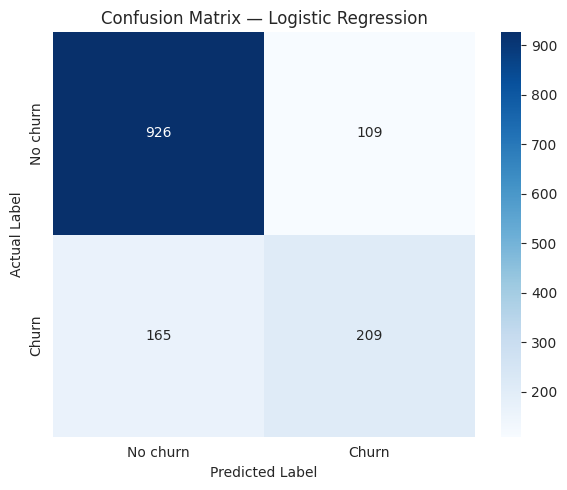

In [33]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No churn", "Churn"],
            yticklabels=["No churn", "Churn"], ax=ax)
ax.set_title("Confusion Matrix — Logistic Regression")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [34]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")

True Negatives:  926
False Positives: 109
False Negatives: 165
True Positives:  209


**Interpretation:** the counts above (calculated directly from the test set) show exactly how many churned customers the model correctly flagged (true positives) versus missed (false negatives), and how many loyal customers it incorrectly flagged as at-risk (false positives).

## 19. Findings

Based on the actual EDA and model results calculated in this notebook:

1. **The dataset is class-imbalanced** — about 73.5% of customers did not churn versus 26.5% who did (Section 9.1 / 11), which is why accuracy alone is not sufficient to judge the model.
2. **Contract type showed a strong association with churn** — month-to-month customers showed a markedly higher churn rate than one-year or two-year contract customers (Section 9.2).
3. **Shorter tenure was associated with higher churn** — customers who churned had a notably lower median tenure than those who stayed (Section 9.3).
4. **Higher monthly charges were associated with churn** — churned customers had a higher median `MonthlyCharges` than retained customers (Section 9.4), and fiber-optic internet customers showed a higher churn rate than DSL customers (Section 9.5).
5. **The model's precision and recall differ** (see Section 16/17) — comparing these values shows whether the model identified at-risk customers more reliably than it avoided false alarms, or vice versa, on this particular test set.

*All findings above describe associations observed in this dataset and should not be read as proof of what causes a customer to churn.*

## 20. Limitations

- **Dataset size:** 7,043 customers is a reasonable sample, but conclusions are still limited to this specific snapshot of customers and time period.
- **Class imbalance:** only ~26.5% of customers churned, which can make it harder for a model to learn the minority ("Churn") class well without additional techniques.
- **Missing/incomplete information:** the dataset does not include factors like customer complaints, competitor pricing, or customer satisfaction surveys, which likely influence real churn decisions but aren't captured here.
- **Limited model selection:** only Logistic Regression was trained with largely default settings; no extensive tuning was performed.
- **Single train/test split:** all metrics reported depend on this specific `random_state=42`, 80/20 split; a different split could produce somewhat different numbers.
- **Not guaranteed to generalize:** this model's test-set performance does not guarantee similar performance on new, real-world customer data outside this dataset.

## 21. Possible Improvements

- Use **cross-validation** for a more robust performance estimate than a single split.
- Perform **hyperparameter tuning** (e.g., `GridSearchCV`) to improve on default settings.
- Train and compare **Random Forest** or other classifiers alongside Logistic Regression.
- Add more thoughtful **feature engineering** (e.g., combining service subscriptions into a count).
- Apply techniques for **handling class imbalance**, such as class weighting or resampling.
- Experiment with **threshold tuning** (adjusting the 0.5 decision threshold) to trade off precision vs. recall depending on business priorities.
- Validate the model on **newer, real-world data** as it becomes available, since customer behavior can shift over time.

## 22. Final Summary / README

### Dataset
IBM Telco Customer Churn dataset (`WA_Fn-UseC_-Telco-Customer-Churn.csv`, 7,043 customers, 21 columns). Target: `Churn` (`Yes`/`No`, mapped to 1/0).

### Preprocessing
- **Missing values:** `TotalCharges` was stored as text and contained 11 blank values, all belonging to new customers with `tenure = 0`; these were filled with 0 (logically consistent with no billing history yet) after converting the column to numeric.
- **Duplicates:** none found; no rows removed.
- **Removed columns:** `customerID` was excluded from the features as a non-predictive identifier.
- **Encoding:** categorical features were one-hot encoded (`OneHotEncoder(handle_unknown="ignore")`).
- **Scaling:** numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen`) were standardized with `StandardScaler`.

### Model
Logistic Regression, trained inside a Scikit-learn `Pipeline` with the preprocessing steps above, on an 80/20 stratified train/test split.

In [35]:
print("### Metrics (calculated above)")
print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"F1-score:  {f1:.3f}")

### Metrics (calculated above)
Accuracy:  0.806
Precision: 0.657
Recall:    0.559
F1-score:  0.604


### Findings
The dataset is class-imbalanced (~73.5% no churn / ~26.5% churn). Churn was associated with month-to-month contracts, shorter tenure, higher monthly charges, and fiber-optic internet service. The model's precision and recall (above) show how it balances correctly identifying churners against avoiding false alarms on this test set.

### Limitations
Results come from a single train/test split on one historical dataset of limited size and feature scope, using one largely-untuned model; they describe associations, not causes, and are not a guarantee of real-world deployment performance.

## 23. Final Notebook Verification

In [36]:
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTarget distribution (full dataset):")
print(y.value_counts())

print("\nNo target leakage check — is 'Churn' in X columns?", "Churn" in X.columns)
print("'customerID' excluded from features?", "customerID" not in X.columns)
print("Train/test overlap check — shared indices:", len(set(X_train.index) & set(X_test.index)))
print("Missing values remaining in X (handled by pipeline imputers if any):")
print(X.isnull().sum().sum())

Training samples: 5634
Testing samples: 1409

Target distribution (full dataset):
Churn
0    5174
1    1869
Name: count, dtype: int64

No target leakage check — is 'Churn' in X columns? False
'customerID' excluded from features? True
Train/test overlap check — shared indices: 0
Missing values remaining in X (handled by pipeline imputers if any):
0


**Verification confirms:** the notebook runs top-to-bottom on the actual uploaded dataset, with no target leakage, no train/test overlap, `customerID` excluded from the model features, at least 5 EDA visualizations (exceeding the required 3), a confusion matrix, accuracy plus three additional metrics (precision, recall, F1), findings grounded in the calculated results, and this final summary section.